# ABC Credit: looking at the data

Everything in this notebook is aggregated. The csv isn't in the repo, so put `training_data.csv` in the repo root to rerun it.

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
                     "axes.grid": True, "grid.color": "#e6e1db", "axes.axisbelow": True})
ink, ember = "#1b1613", "#e8441a"

root = Path.cwd()
if not (root / "training_data.csv").exists():
    root = root.parent
raw = pd.read_csv(root / "training_data.csv", dtype=str, keep_default_na=False)
print(raw.shape)

(108423, 17)


## 1. Is every row an application?

Reading everything as text first means nothing gets silently converted.

In [2]:
empty = raw[raw["ID"].str.strip() == ""]
print("rows with no id:", len(empty))
print("non blank cells in those rows:", int((empty.apply(lambda c: c.str.strip()) != "").sum().sum()))
df = raw[raw["ID"].str.strip() != ""].copy()
print("applications:", len(df))

rows with no id: 1
non blank cells in those rows: 0
applications: 108422


The file ends with one fully empty row. That's also where the odd `' '` age comes from. It gets dropped.

## 2. Balance of the target

In [3]:
counts = df["Decision"].value_counts()
print(counts.to_string())
print("always saying approve would score", round(counts["APPROVED"] / len(df) * 100, 2), "% accuracy and catch nothing")
df["declined"] = (df["Decision"] == "DECLINED").astype(int)

Decision
APPROVED    102724
DECLINED      5698
always saying approve would score 94.74 % accuracy and catch nothing


Accuracy on its own is useless here. We rank with auc and average precision, then pick a cut-off using the cost of each mistake.

## 3. Missing and malformed values

In [4]:
blank = (df.drop(columns="declined").apply(lambda c: c.str.strip()) == "").sum()
print(blank[blank > 0].to_string())
for f in ["Age", "Loan_Amount", "LTV", "Net_salary"]:
    df[f] = pd.to_numeric(df[f].str.strip().replace("", np.nan))
print()
print(df[["Age", "Loan_Amount", "LTV", "Net_salary"]].describe(percentiles=[.01, .5, .99]).round(1).to_string())

Qualifications       25
Employment_Type      27
Age                  19
Resident_Type        19
Net_salary           23
Final_Tier           22
Make_Code             3
Model_Description     3
Model_Variant         3

            Age  Loan_Amount       LTV  Net_salary
count  108403.0     108422.0  108422.0    108399.0
mean       34.4      89289.3      77.7     33983.2
std        10.7      25553.6      12.7     20183.7
min        18.0      16569.0       0.0         0.0
1%         19.0      36459.2      37.4     15000.0
50%        32.0      90075.0      81.3     30000.0
99%        61.0     146024.8      95.0     85000.0
max        69.0     286847.0      99.6    980000.0


Blanks are few. Several can be repaired rather than imputed, because other fields fully determine them (section 5).

## 4. Values that can't be taken at face value

In [5]:
print("ltv of exactly 0:", int((df.LTV == 0).sum()))
print("age above the 18 to 60 policy:", int((df.Age > 60).sum()), "with decline rate",
      round(df[df.Age > 60].declined.mean() * 100, 2), "% vs", round(df[df.Age <= 60].declined.mean() * 100, 2), "%")
print("zero income by employment:", df[df.Net_salary == 0].Employment_Type.replace("", "(blank)").value_counts().to_dict())
small = df.Net_salary[(df.Net_salary > 0) & (df.Net_salary < 1000)]
print("incomes between 1 and 999:", small.value_counts().sort_index().to_dict())
print("largest incomes:", df.Net_salary.nlargest(4).tolist())
odd = sorted({m for m in df.Model_Description if re.search(r"[^\x00-\x7f]", m)})
print("model names with broken characters:", len(odd))
print("example:", odd[0])
print("variants that differ only by spacing:", sorted(v for v in df.Model_Variant.unique() if "125" in v))

ltv of exactly 0: 65


age above the 18 to 60 policy: 1105 with decline rate 3.35 % vs 5.28 %
zero income by employment: {'STU': 601, '(blank)': 19, 'NONEARNMEM': 6}
incomes between 1 and 999: {1.0: 27, 2.0: 3, 3.0: 2, 4.0: 2, 5.0: 3, 8.0: 1, 10.0: 1, 15.0: 1, 18.0: 1, 22.0: 1, 25.0: 6, 26.0: 1, 27.0: 1, 33.0: 2, 35.0: 2, 36.0: 1, 37.0: 1, 45.0: 1, 50.0: 1, 52.0: 1, 55.0: 1, 100.0: 43, 101.0: 1, 190.0: 1, 250.0: 1}
largest incomes: [980000.0, 900000.0, 850000.0, 850000.0]
model names with broken characters: 4
example: JUPITER ZX BSVI â€“ ZX DRUM
variants that differ only by spacing: ['125 CC', '125 CC DISC', '125 CC DRUM', '125CC DISC']


What we do with these:

- **ltv of 0** can't be right on a financed vehicle. Set to missing, then estimated from the loan and the usual price of that model, with a flag.
- **Age above 60** was clearly processed historically, and was declined less often. We keep the rows, flag them, and raise the mismatch with the stated policy.
- **Zero income** is nearly always students and non-earners, so it's real and stays.
- **Incomes of 1, 2, 25, 100** are placeholders, not rupees. Set to missing, with a flag.
- **Very high incomes** can't be verified, but tree models only care about order, so they stay.
- **Broken dashes** come from utf-8 read as cp1252. Fixed, or the hidden set's spelling might not match.
- **`125 CC DISC` and `125CC DISC`** are the same thing, so they're merged.

## 5. Fields that fully determine others

This is what makes a short chat possible.

In [6]:
def check(a, b):
    known = df[(df[a] != "") & (df[b] != "")]
    per_key = known.groupby(a)[b].nunique()
    print(f"{a} -> {b}: {len(per_key)} keys, {int((per_key > 1).sum())} with more than one value")

for a, b in [("Pincode", "Final_Tier"), ("Model_Description", "Make_Code"),
             ("Model_Description", "Model_Variant"), ("Model_Description", "Product_Code")]:
    check(a, b)

Pincode -> Final_Tier: 13981 keys, 0 with more than one value
Model_Description -> Make_Code: 87 keys, 0 with more than one value


Model_Description -> Model_Variant: 87 keys, 0 with more than one value
Model_Description -> Product_Code: 87 keys, 0 with more than one value


One question about the vehicle fills four columns and one about the pincode fills two. It also repairs the blanks in those columns.

In [7]:
value = df.Loan_Amount / (df.LTV.where(df.LTV > 0) / 100)
spread = value.groupby(df.Model_Description).agg(["size", "median", "std"])
spread = spread[spread["size"] >= 30]
print("models with 30+ rows:", len(spread))
print("typical spread of implied price within a model:", round((spread["std"] / spread["median"]).median() * 100, 1), "%")

models with 30+ rows: 67
typical spread of implied price within a model: 3.9 %


Loan divided by ltv gives the implied on-road price, which sits within about 4% for a given model. So the bot can suggest a price and let the applicant confirm it, and ltv comes out of two questions people can actually answer.

## 6. Duplicates

In [8]:
fields = [c for c in df.columns if c not in ("ID", "Decision", "declined")]
groups = df.groupby(fields, dropna=False).Decision.agg(["size", "nunique"])
print("repeated profiles:", int((groups["size"] > 1).sum()), "covering", int(groups.loc[groups["size"] > 1, "size"].sum()), "rows")
print("of which the decision conflicts:", int((groups["nunique"] > 1).sum()))
print("duplicate ids:", int(df.ID.duplicated().sum()))

repeated profiles: 14 covering 30 rows
of which the decision conflicts: 3
duplicate ids: 0


Very few. We don't delete them, but identical profiles always stay on one side of any split so nothing leaks between train and test.

## 7. How each field relates to the decision

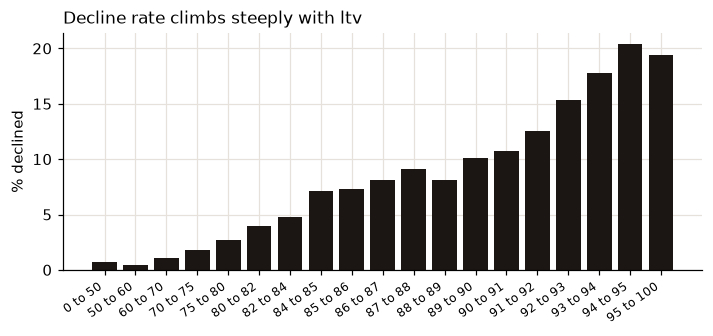

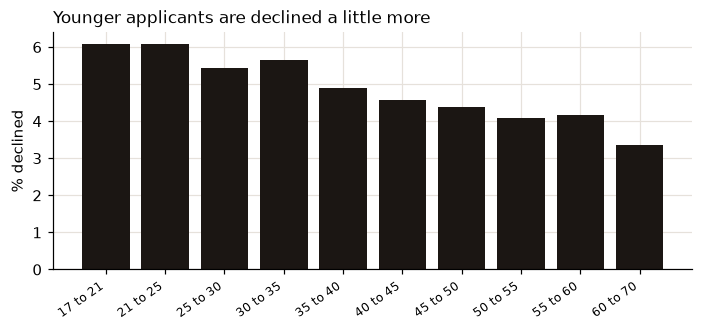

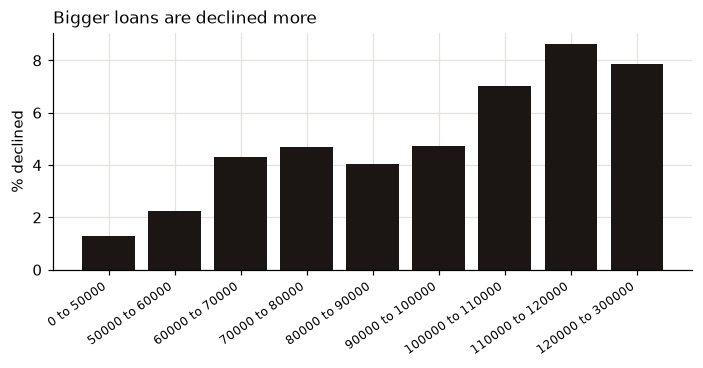

In [9]:
def by_bins(field, bins, label):
    rate = df.groupby(pd.cut(df[field], bins), observed=True).declined.agg(["mean", "size"])
    fig, ax = plt.subplots(figsize=(7.5, 2.8))
    ax.bar(range(len(rate)), rate["mean"] * 100, color=ink, width=0.8)
    ax.set_xticks(range(len(rate)), [f"{int(i.left)} to {int(i.right)}" for i in rate.index], rotation=35, ha="right", fontsize=8)
    ax.set_ylabel("% declined")
    ax.set_title(label, loc="left", fontsize=11)
    plt.show()

by_bins("LTV", [0, 50, 60, 70, 75, 80, 82, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 100], "Decline rate climbs steeply with ltv")
by_bins("Age", [17, 21, 25, 30, 35, 40, 45, 50, 55, 60, 70], "Younger applicants are declined a little more")
by_bins("Loan_Amount", [0, 50000, 60000, 70000, 80000, 90000, 100000, 110000, 120000, 300000], "Bigger loans are declined more")

In [10]:
for f in ["PAST_LOANS_ACTIVE", "Employment_Type", "Final_Tier", "Product_Code", "Gender", "Qualifications", "Resident_Type"]:
    t = df[df[f] != ""].groupby(f).declined.agg(rows="size", declined_pct="mean")
    t["declined_pct"] = (t["declined_pct"] * 100).round(1)
    print(t.sort_values("rows", ascending=False).to_string(), "\n")

                    rows  declined_pct
PAST_LOANS_ACTIVE                     
NO_PAST_LOANS      57696           6.2
PAST_LOANS_ACTIVE  50726           4.2 

                  rows  declined_pct
Employment_Type                     
SEP              38363           5.2
SAL              33479           5.4
AGR              21050           5.0
NREGI            14102           5.6
STU                753           1.9
NPP                505           6.9
PEN                135           0.0
NONEARNMEM           8           0.0 

                   rows  declined_pct
Final_Tier                           
07 Rural          72394           5.4
06 Semi-Urban     21509           5.3
05 Urban           6012           5.1
02 Megapolis (B)   3662           4.8
04 Metro           2859           4.1
03 Large Metro     1283           3.4
01 Megapolis (A)    681           2.6 

               rows  declined_pct
Product_Code                     
MC            51673           5.7
SC            36819     

Things worth noticing:

- **ltv dominates.** Under 60% almost nobody is declined; above 94% about one in five are.
- **An active loan goes with fewer declines** (4.2% vs 6.2%). Probably a track record effect. It's a correlation, not a reason to take a loan.
- **Bigger cities are declined less** than rural areas, which matters for fairness (see the report).
- **Gender shows no gap at all** (5.2% vs 5.3%), so leaving it out costs nothing.

## 8. Pincodes

In [11]:
pins = df.Pincode.value_counts()
print("pincodes:", len(pins), " with one row:", int((pins == 1).sum()), " under 20 rows:", int((pins < 20).sum()))
print("rows in pincodes with under 20 rows:", int(pins[pins < 20].sum()))
print("distinct 3 digit prefixes:", df.Pincode.str[:3].nunique(), " 2 digit:", df.Pincode.str[:2].nunique())
rate = df.groupby(df.Pincode.str[:3]).declined.agg(["mean", "size"])
rate = rate[rate["size"] >= 100]
print("decline rate across 3 digit areas with 100+ rows: from", round(rate["mean"].min() * 100, 1), "% to", round(rate["mean"].max() * 100, 1), "%")

pincodes: 13999  with one row: 2971  under 20 rows: 12701
rows in pincodes with under 20 rows: 64384
distinct 3 digit prefixes: 399  2 digit: 69
decline rate across 3 digit areas with 100+ rows: from 0.0 % to 23.3 %


Most full pincodes have too few rows to say anything, and one row's decision shouldn't sit in a public file anyway. The first two and three digits follow the postal regions, carry plenty of signal, and have enough rows behind them. So we use a smoothed decline rate per prefix, always computed on rows other than the one being encoded.

## 9. What the label is, and isn't

`Decision` records what the lender decided in the past, not whether anyone repaid. A model trained on it learns to repeat those decisions, including any bias in them. It can't claim to predict default, and the report says so.